# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [3]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [4]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,14.189159,7.205170,S-G1
1,1,osimertinib,B,tago-01560,1.031097,13.491245,P
2,2,osimertinib,A,tago-02253,14.651874,7.435656,S-G1
3,3,osimertinib,A,tago-01478,13.919818,-3.705924,S-syn
4,4,osimertinib,A,tago-02626,14.527276,6.953301,S-G1


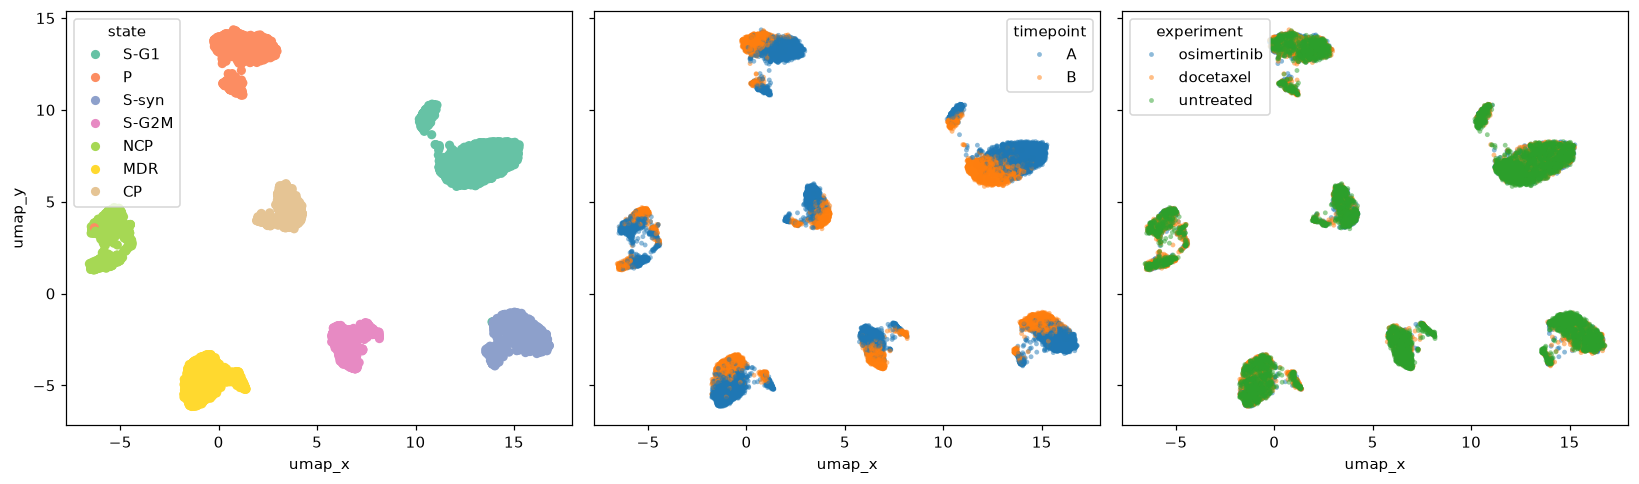

In [5]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [6]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [7]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [8]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [9]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [10]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [11]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

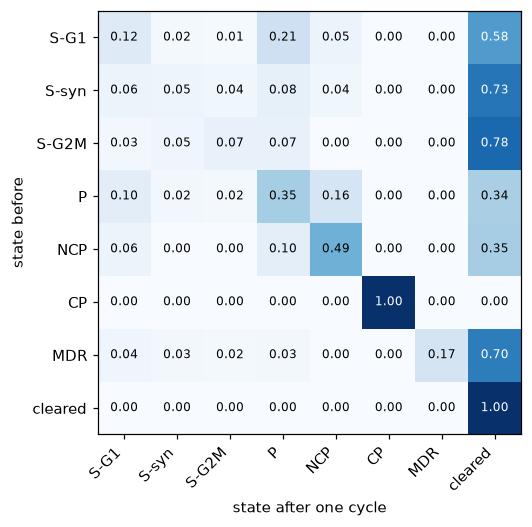

In [12]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

*Answer here.*
From the matrix seems like CP is amn absorbing state under osimertinib. Since estimated probability after one cycle is one and there is no (zero) probability to transition to the other states this simply indicates the drug osimertinib may not be effective against CP state by itself 


## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

Probability indicates no starting states are completely eliminated but S-Syn and SG2-M have the highest probability of getting cleared. CP has probability 1 (certain); it transitions back to itself and stays in the same state despite multiple rounds of the osi treatment.

The cells that have probability of transitioning into themselves are P, NCP, MDR

In [13]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [14]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [15]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

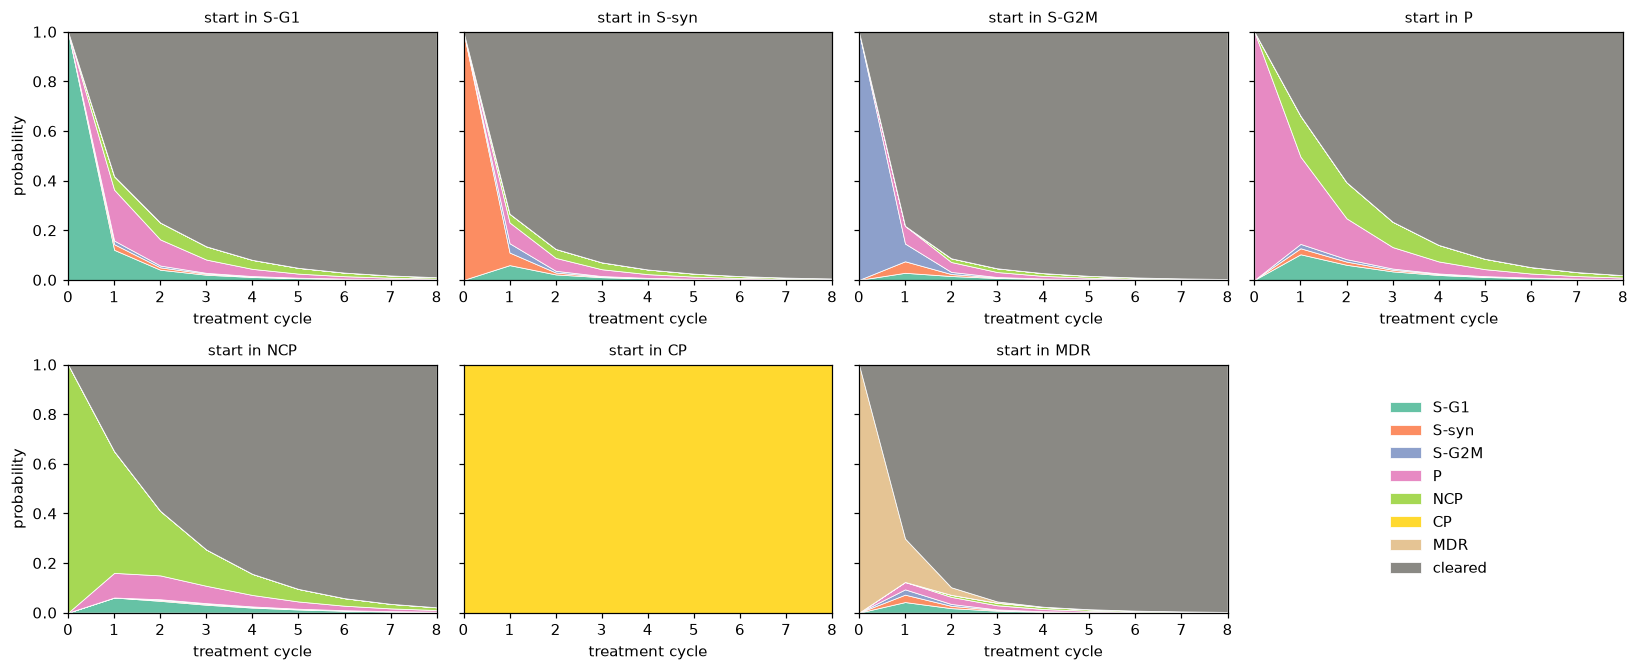

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [16]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

In [17]:
alive3 = {
    s: 1 - evolve(basis(s, P_hat), P_hat, 3)[-1, -1]
    for s in STATES
}

pd.Series(alive3).sort_values(ascending=False)

CP       1.000000
NCP      0.254336
P        0.234360
S-G1     0.135156
S-syn    0.070709
S-G2M    0.046717
MDR      0.045077
dtype: float64

In [18]:
print("Fraction alive after 8 cycles:")
for s in STATES:
    traj = evolve(basis(s, P_hat), P_hat, 8)
    print(f"  {s:6s}: {1 - traj[-1, -1]:.4f}")

Fraction alive after 8 cycles:
  S-G1  : 0.0108
  S-syn : 0.0056
  S-G2M : 0.0036
  P     : 0.0190
  NCP   : 0.0216
  CP    : 1.0000
  MDR   : 0.0029


<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



1. After eight cycles of osimertinib, none of the seven starting states is completely eliminated, since all have a nonzero probability of survival. However, S-G1, S-syn, S-G2M, P, NCP, and MDR have very low survival probabilities compared with CP.

2. Among the non-CP starting states, NCP lasts the longest, with approximately 2.16% of cells still alive after eight cycles.

3. CP is the most persistent state because it is absorbing, meaning cells starting in CP remain there under osimertinib. Excluding CP, NCP shows the highest survival after eight cycles.

4. CP has the highest survival after three cycles at 100%. Excluding CP, NCP has the highest survival proportion at approximately 25.43%, followed by P at 23.44%..


### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

In [19]:
# Your code here

pi_mix = (
    cells[cells["timepoint"] == "A"]["state"]
    .value_counts(normalize=True)
    .reindex(OUTCOMES, fill_value=0)
    .to_numpy()
)

pi_mix  # TODO: set this equal to the starting vector from timepoint A

# evolve pi_mix and plot the results

array([0.247     , 0.14833333, 0.09944444, 0.15255556, 0.10244444,
       0.09722222, 0.153     , 0.        ])

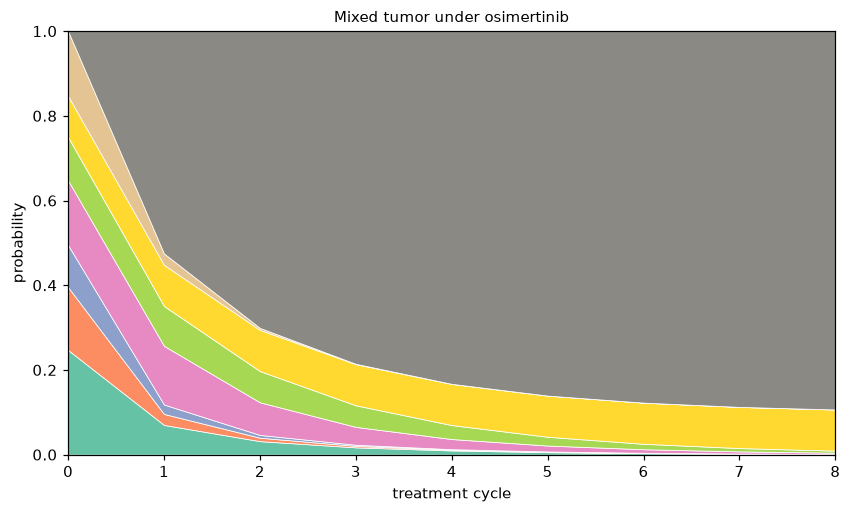

In [20]:
traj_mix = evolve(pi_mix, P_hat, 8)

fig, ax = plt.subplots(figsize=(9, 5))
plot_trajectory(traj_mix, ax, "Mixed tumor under osimertinib")
ax.set_ylabel("probability")
plt.show()

<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

**1. What state ends up dominating the remaining cell population?**

CP dominates the remaining living cell population after repeated cycles of osimertinib. P and NCP also tend to survive longer than other non-CP states because they have relatively high probabilities of staying in the same state or transitioning between each other.

**2. Will these cells ever be cleared?**

CP cells will not be cleared under osimertinib because CP is an absorbing state. Once a cell enters CP, it stays there. P and NCP cells can still be cleared, but their tendency to remain in or move between persister states slows down the process.

**3. How does the long-run endpoint relate to the transition matrix?**

The transition matrix shows that CP and cleared are absorbing states, meaning cells cannot leave them once they enter. As treatment cycles continue, the probabilities of being in the other states decrease, and the population eventually approaches a mixture of CP and cleared cells. The final proportions depend on the starting distribution and the transition probabilities.

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [21]:
##Add code here
# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position
P_osi = P_hat.to_numpy()
def make_transition_matrix(experiment):
    data = cells[cells["experiment"] == experiment]

    A = data[data["timepoint"] == "A"][["lineage_tag", "state"]]
    B = data[data["timepoint"] == "B"][["lineage_tag", "state"]]

    pairs = pd.merge(A, B, on="lineage_tag",
                     how="left", suffixes=("_A", "_B"))

    pairs["state_B"] = pairs["state_B"].fillna("cleared")

    counts = pd.crosstab(pairs["state_A"], pairs["state_B"])
    counts = counts.reindex(index=OUTCOMES, columns=OUTCOMES, fill_value=0)

    # Cleared remains cleared
    counts.loc["cleared", "cleared"] = 1

    return counts.div(counts.sum(axis=1), axis=0).to_numpy()

P_doc = make_transition_matrix("docetaxel")       # TODO

P_holiday = make_transition_matrix("untreated")  # TODO

In [22]:
print("Docetaxel:")
display(pd.DataFrame(P_doc, index=OUTCOMES, columns=OUTCOMES).round(2))

print("Drug holiday:")
display(pd.DataFrame(P_holiday, index=OUTCOMES, columns=OUTCOMES).round(2))

Docetaxel:


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
S-G1,0.29,0.10,0.02,0.09,0.08,0.0,0.04,0.38
S-syn,0.05,0.11,0.14,0.05,0.03,0.0,0.00,0.62
S-G2M,0.03,0.02,0.04,0.02,0.02,0.0,0.00,0.87
P,0.09,0.04,0.02,0.41,0.07,0.0,0.01,0.35
NCP,0.08,0.00,0.00,0.09,0.44,0.0,0.02,0.37
CP,0.08,0.03,0.03,0.03,0.00,0.1,0.00,0.72
MDR,0.00,0.00,0.00,0.00,0.00,0.0,1.00,0.00
cleared,0.00,0.00,0.00,0.00,0.00,0.0,0.00,1.00


Drug holiday:


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
S-G1,0.41,0.43,0.11,0.00,0.00,0.00,0.00,0.05
S-syn,0.09,0.34,0.52,0.00,0.00,0.00,0.00,0.05
S-G2M,0.57,0.10,0.27,0.00,0.00,0.00,0.00,0.06
P,0.41,0.10,0.05,0.32,0.05,0.00,0.00,0.06
NCP,0.19,0.07,0.00,0.23,0.48,0.00,0.00,0.04
CP,0.06,0.03,0.04,0.00,0.00,0.82,0.00,0.05
MDR,0.32,0.04,0.04,0.00,0.00,0.00,0.54,0.05
cleared,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00


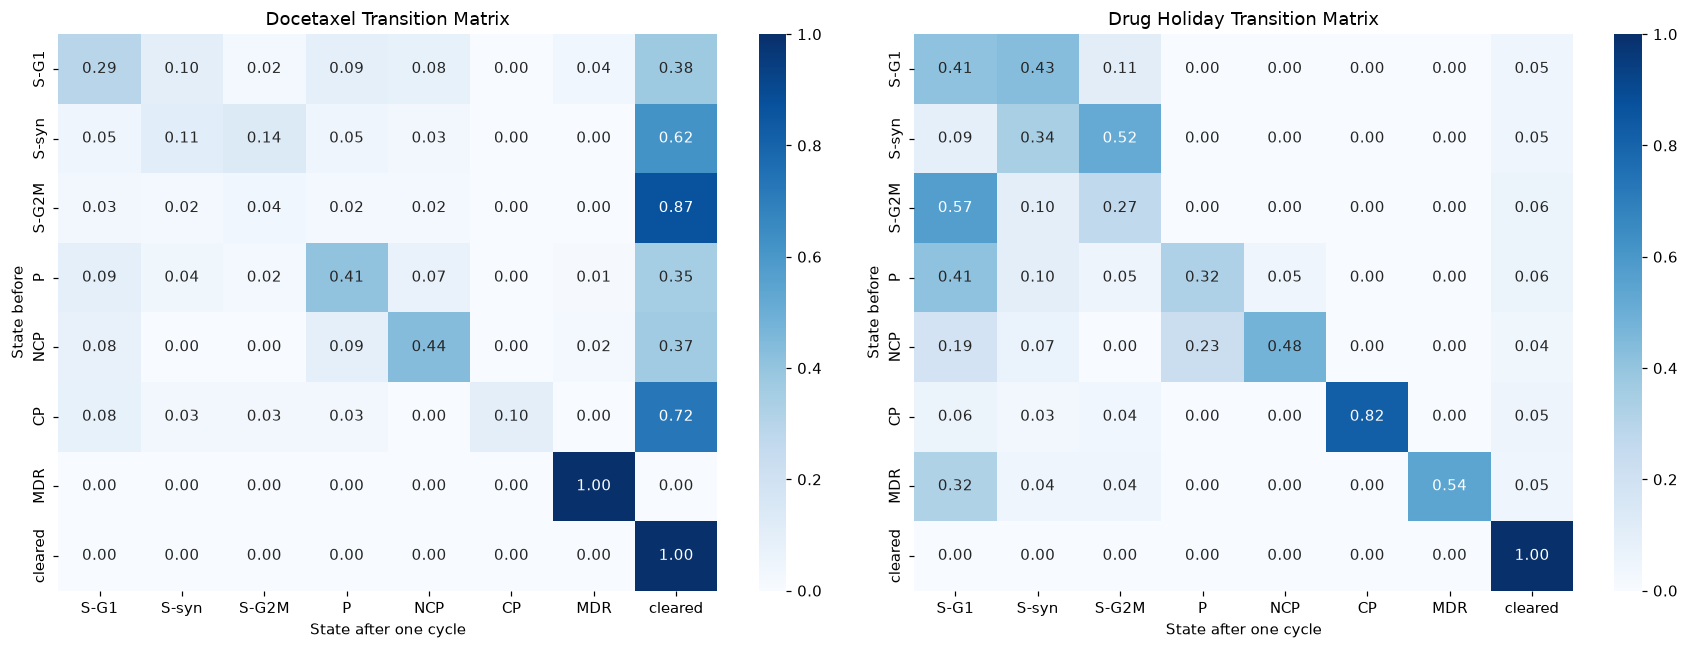

In [23]:
#Plot the transition matrices for docetaxel and the drug holiday.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    P_doc,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=OUTCOMES,
    yticklabels=OUTCOMES,
    vmin=0,
    vmax=1,
    ax=axes[0]
)
axes[0].set_title("Docetaxel Transition Matrix")
axes[0].set_xlabel("State after one cycle")
axes[0].set_ylabel("State before")

sns.heatmap(
    P_holiday,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=OUTCOMES,
    yticklabels=OUTCOMES,
    vmin=0,
    vmax=1,
    ax=axes[1]
)
axes[1].set_title("Drug Holiday Transition Matrix")
axes[1].set_xlabel("State after one cycle")
axes[1].set_ylabel("State before")

plt.tight_layout()
plt.show()

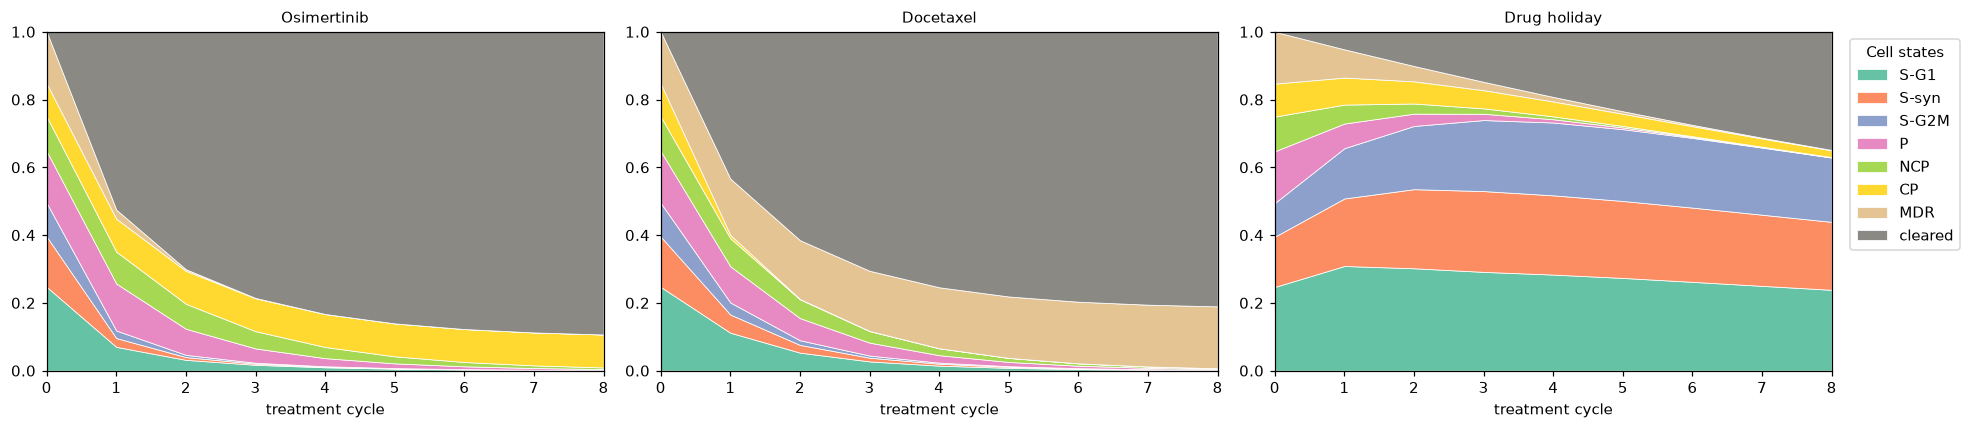

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


In [24]:
# Simulate the evolution of pi_mix under docetaxel 
traj_osi = evolve(pi_mix, P_osi, 8)
traj_doc = evolve(pi_mix, P_doc, 8)
traj_holiday = evolve(pi_mix, P_holiday, 8)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

plot_trajectory(traj_osi, axes[0], "Osimertinib")
plot_trajectory(traj_doc, axes[1], "Docetaxel")
plot_trajectory(traj_holiday, axes[2], "Drug holiday")
axes[2].legend(
    OUTCOMES,
    title="Cell states",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.show()


pd.DataFrame(traj_doc, columns=OUTCOMES).round(3)

In [55]:
print("Docetaxel row sums:", P_doc.sum(axis=1))
print("Drug holiday row sums:", P_holiday.sum(axis=1))

Docetaxel row sums: [1. 1. 1. 1. 1. 1. 1. 1.]
Drug holiday row sums: [1. 1. 1. 1. 1. 1. 1. 1.]


*Answer questions in markdown here.*
**1. Comparing the transition matrices**

- **Osimertinib:** CP and cleared are absorbing states. CP cells remain in CP, while many other cell states have high probabilities of being cleared.

- **Docetaxel:** MDR and cleared are absorbing states. Most cell states have relatively high probabilities of being cleared, especially S-G2M. However, MDR cells remain resistant, and some other cells can transition into MDR.

- **Drug holiday:** Cleared is the only absorbing state. Without treatment, cells are less likely to be cleared and more likely to remain in or transition between living states. For example, S-G1 frequently transitions to S-syn, and S-syn frequently transitions to S-G2M.

Overall, osimertinib and docetaxel have different resistant states, while the drug holiday allows more transitions between living cell states.


 

**2. Mixed tumor under docetaxel**

After eight cycles of docetaxel, approximately 81% of the original tumor is cleared. MDR becomes the dominant surviving state, making up about 96% of the remaining living cells.

This happens because MDR is an absorbing state under docetaxel. Cells already in MDR remain there, and some cells from other states can also transition into MDR.

As a result, the proportion of the original tumor in MDR increases from approximately 15.3% to 18.3%, while most other living cell states decrease over repeated treatment cycles.



## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

In [25]:
## Add code here
# Eight cycles of a single drug
osi_8 = pi_mix @ np.linalg.matrix_power(P_osi, 8)
doc_8 = pi_mix @ np.linalg.matrix_power(P_doc, 8)

# Eight cycles alternating drugs (4 pairs)
osi_doc_8 = pi_mix @ np.linalg.matrix_power(P_osi @ P_doc, 4)
doc_osi_8 = pi_mix @ np.linalg.matrix_power(P_doc @ P_osi, 4)

# Compare the fraction cleared
results = pd.Series({
    "Osimertinib x 8": osi_8[-1],
    "Docetaxel x 8": doc_8[-1],
    "Osi → Doc alternating": osi_doc_8[-1],
    "Doc → Osi alternating": doc_osi_8[-1]
})

print("Fraction cleared after 8 cycles:")
print(results.sort_values(ascending=False).round(4))

Fraction cleared after 8 cycles:
Doc → Osi alternating    0.9908
Osi → Doc alternating    0.9906
Osimertinib x 8          0.8934
Docetaxel x 8            0.8104
dtype: float64


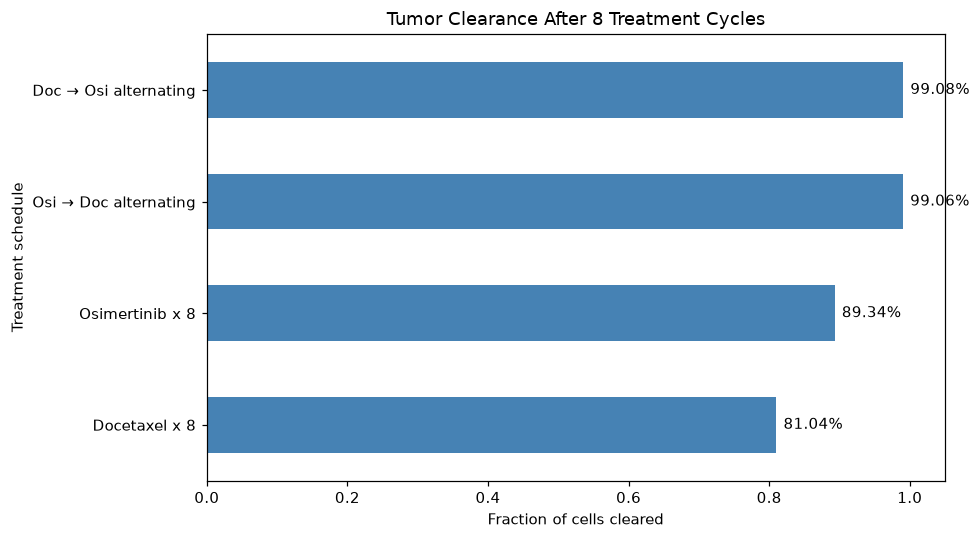

In [26]:
plt.figure(figsize=(9, 5))

results.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.xlabel("Fraction of cells cleared")
plt.ylabel("Treatment schedule")
plt.title("Tumor Clearance After 8 Treatment Cycles")
plt.xlim(0, 1.05)

for i, value in enumerate(results.sort_values()):
    plt.text(value + 0.01, i, f"{value:.2%}", va="center")

plt.tight_layout()
plt.show()

In [27]:
matrices_8 = {
    "Osimertinib x 8": np.linalg.matrix_power(P_osi, 8),
    "Docetaxel x 8": np.linalg.matrix_power(P_doc, 8),
    "Osi → Doc alternating": np.linalg.matrix_power(P_osi @ P_doc, 4),
    "Doc → Osi alternating": np.linalg.matrix_power(P_doc @ P_osi, 4)
}

for name, matrix in matrices_8.items():
    print(f"\n{name}")
    display(
        pd.DataFrame(
            matrix,
            index=OUTCOMES,
            columns=OUTCOMES
        ).round(4)
    )


Osimertinib x 8


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
S-G1,0.0015,0.0002,0.0002,0.0035,0.0055,0.0,0.0,0.9892
S-syn,0.0008,0.0001,0.0001,0.0018,0.0029,0.0,0.0,0.9944
S-G2M,0.0005,0.0001,0.0001,0.0012,0.0018,0.0,0.0,0.9964
P,0.0026,0.0004,0.0003,0.0061,0.0097,0.0,0.0,0.9810
NCP,0.0029,0.0004,0.0003,0.0068,0.0111,0.0,0.0,0.9784
CP,0.0000,0.0000,0.0000,0.0000,0.0000,1.0,0.0,0.0000
MDR,0.0004,0.0001,0.0000,0.0010,0.0015,0.0,0.0,0.9971
cleared,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0,1.0000



Docetaxel x 8


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
S-G1,0.0022,0.0008,0.0004,0.0034,0.0033,0.0,0.0625,0.9273
S-syn,0.0009,0.0003,0.0002,0.0014,0.0013,0.0,0.0083,0.9876
S-G2M,0.0004,0.0001,0.0001,0.0006,0.0006,0.0,0.0041,0.9941
P,0.0028,0.0011,0.0006,0.0045,0.0042,0.0,0.0413,0.9455
NCP,0.0031,0.0011,0.0006,0.0048,0.0049,0.0,0.0536,0.9319
CP,0.0006,0.0002,0.0001,0.0010,0.0009,0.0,0.0072,0.9899
MDR,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,1.0000,0.0000
cleared,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0000,1.0000



Osi → Doc alternating


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
S-G1,0.0018,0.0005,0.0003,0.0032,0.0036,0.0000,0.0006,0.9901
S-syn,0.0009,0.0003,0.0001,0.0016,0.0019,0.0000,0.0003,0.9949
S-G2M,0.0006,0.0002,0.0001,0.0010,0.0011,0.0000,0.0002,0.9968
P,0.0030,0.0009,0.0005,0.0054,0.0062,0.0000,0.0010,0.9830
NCP,0.0033,0.0010,0.0005,0.0059,0.0071,0.0000,0.0011,0.9810
CP,0.0012,0.0004,0.0002,0.0021,0.0021,0.0001,0.0003,0.9936
MDR,0.0007,0.0003,0.0001,0.0013,0.0012,0.0000,0.0012,0.9952
cleared,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000



Doc → Osi alternating


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
S-G1,0.0016,0.0003,0.0003,0.0038,0.0047,0.0000,0.0002,0.9891
S-syn,0.0007,0.0001,0.0001,0.0016,0.0020,0.0000,0.0001,0.9953
S-G2M,0.0003,0.0001,0.0000,0.0007,0.0009,0.0000,0.0000,0.9979
P,0.0023,0.0005,0.0004,0.0053,0.0066,0.0000,0.0003,0.9846
NCP,0.0025,0.0005,0.0004,0.0058,0.0076,0.0000,0.0003,0.9828
CP,0.0005,0.0001,0.0001,0.0012,0.0014,0.0001,0.0001,0.9964
MDR,0.0011,0.0004,0.0003,0.0023,0.0022,0.0000,0.0010,0.9927
cleared,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000


In [28]:
clearance = pd.DataFrame({
    name: matrix[:, -1]
    for name, matrix in matrices_8.items()
}, index=OUTCOMES)

print("Probability of clearance after 8 cycles:")
display(clearance.round(4))

Probability of clearance after 8 cycles:


,Osimertinib x 8,Docetaxel x 8,Osi → Doc alternating,Doc → Osi alternating
S-G1,0.9892,0.9273,0.9901,0.9891
S-syn,0.9944,0.9876,0.9949,0.9953
S-G2M,0.9964,0.9941,0.9968,0.9979
P,0.9810,0.9455,0.9830,0.9846
NCP,0.9784,0.9319,0.9810,0.9828
CP,0.0000,0.9899,0.9936,0.9964
MDR,0.9971,0.0000,0.9952,0.9927
cleared,1.0000,1.0000,1.0000,1.0000


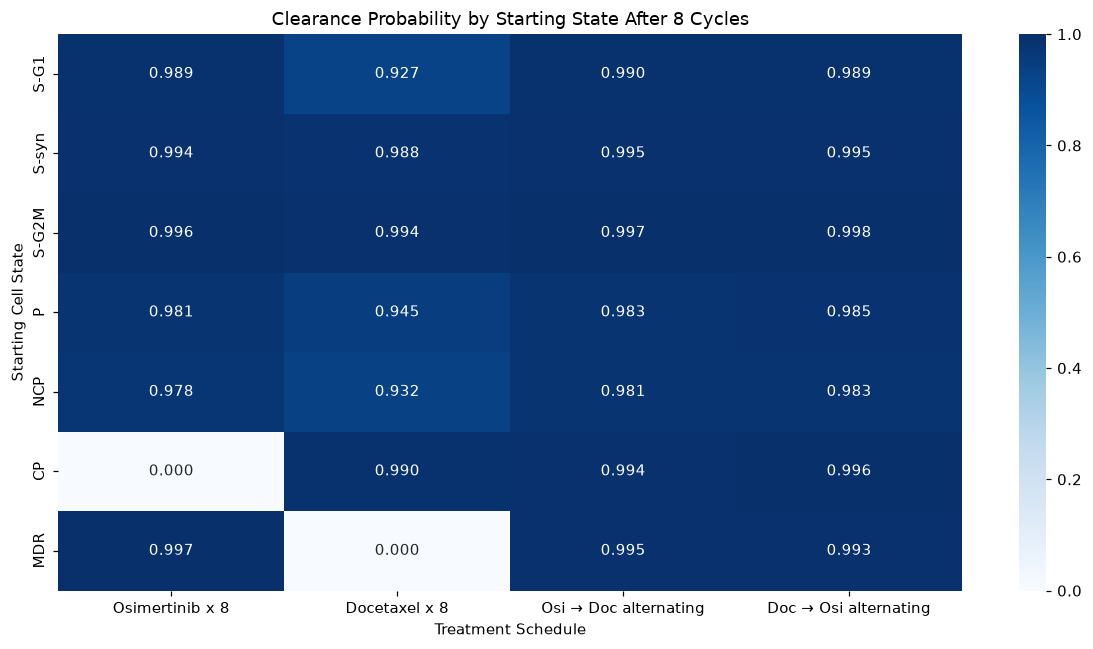

In [29]:
plt.figure(figsize=(11, 6))

sns.heatmap(
    clearance.drop(index="cleared"),
    annot=True,
    fmt=".3f",
    cmap="Blues",
    vmin=0,
    vmax=1
)

plt.title("Clearance Probability by Starting State After 8 Cycles")
plt.xlabel("Treatment Schedule")
plt.ylabel("Starting Cell State")
plt.tight_layout()
plt.show()

In [56]:
holiday_schedules = {
    "Docetaxel x 8": [P_doc] * 8,
    "Holiday then Doc x 7": [P_holiday] + [P_doc] * 7,
    "Doc then Holiday x 4": [P_doc, P_holiday] * 4,
    "Osi then Holiday x 4": [P_osi, P_holiday] * 4,
    "Osi then Doc x 4": [P_osi, P_doc] * 4
}

holiday_results = {}

for name, schedule in holiday_schedules.items():
    pi = pi_mix.copy()

    for P in schedule:
        pi = pi @ P

    holiday_results[name] = pi[-1]

display(
    pd.Series(holiday_results, name="Fraction cleared")
    .sort_values(ascending=False)
    .round(4)
)

Osi then Doc x 4        0.9906
Osi then Holiday x 4    0.9160
Doc then Holiday x 4    0.9072
Holiday then Doc x 7    0.8780
Docetaxel x 8           0.8104
Name: Fraction cleared, dtype: float64

In [57]:
rows = []

for state in STATES:
    for n in [4, 6, 8]:
        schedules = {
            "Osimertinib": [P_osi] * n,
            "Docetaxel": [P_doc] * n,
            "Osi → Doc": [
                P_osi if i % 2 == 0 else P_doc
                for i in range(n)
            ],
            "Doc → Osi": [
                P_doc if i % 2 == 0 else P_osi
                for i in range(n)
            ]
        }

        for name, schedule in schedules.items():
            pi = basis(state, P_hat)

            for P in schedule:
                pi = pi @ P

            rows.append({
                "Starting state": state,
                "Cycles": n,
                "Treatment": name,
                "Clearance %": pi[-1] * 100
            })

prescription_results = pd.DataFrame(rows)

display(
    prescription_results.sort_values(
        ["Starting state", "Clearance %"],
        ascending=[True, False]
    ).round(2)
)

,Starting state,Cycles,Treatment,Clearance %
71,CP,8,Doc → Osi,99.64
70,CP,8,Osi → Doc,99.36
69,CP,8,Docetaxel,98.99
67,CP,6,Doc → Osi,98.91
65,CP,6,Docetaxel,98.42
...,...,...,...,...
17,S-syn,6,Docetaxel,97.97
15,S-syn,4,Doc → Osi,96.01
12,S-syn,4,Osimertinib,95.81
14,S-syn,4,Osi → Doc,95.72


In [58]:
target = 95

eligible = prescription_results[
    prescription_results["Clearance %"] >= target
]

best = (
    eligible.sort_values(
        ["Starting state", "Cycles", "Clearance %"],
        ascending=[True, True, False]
    )
    .drop_duplicates("Starting state")
)

display(
    best[[
        "Starting state",
        "Treatment",
        "Cycles",
        "Clearance %"
    ]].sort_values("Starting state")
)

,Starting state,Treatment,Cycles,Clearance %
61,CP,Docetaxel,4,96.538570
72,MDR,Osimertinib,4,97.625247
55,NCP,Doc → Osi,6,95.081393
43,P,Doc → Osi,6,95.568595
6,S-G1,Osi → Doc,6,97.142943
27,S-G2M,Doc → Osi,4,98.291996
15,S-syn,Doc → Osi,4,96.014307


### Q1. How does alternating between osimertinib and docetaxel compare with using either drug alone?

Alternating between osimertinib and docetaxel gives better results than using either drug alone. After eight cycles, alternating treatment clears approximately 99% of the tumor, compared with 89.34% for osimertinib alone and 81.04% for docetaxel alone.

This is because the two drugs target different absorbing states. CP is resistant to osimertinib, MDR is resistant to docetaxel. Alternating treatments helps clear cells that survive the other drug.

### Q2. Does the order of treatment matter?

The order of treatment makes very little difference for this mixed tumor. Starting with docetaxel clears 99.08% of the cells, compared with 99.06% when starting with osimertinib. The difference is only 0.02 percentage points, so we could say both altermating schedules perform almost equally well.

### Q3. In what situation would a drug holiday help clear the tumor?
A drug holiday may help when cells that are resistant to a drug change into states where that drug is more effective. This means that when treatment resumes, those cells may have a higher chance of being cleared.In our simulation, alternating docetaxel with drug holidays cleared about 90.72% of the tumor, compared with 81.04% using docetaxel alone. This suggests that taking breaks can sometimes improve clearance.

alternating osimertinib and docetaxel gave the best result, clearing approximately 99.06% of the tumor. So while drug holidays may be useful in certain situations, switching between the two drugs was more effective for this mixed tumor.

### Q4. What treatment schedule would you recommend for each starting cell state, and how many cycles?

Based on the simulation, I would recommend different treatment schedules depending on the tumor's starting cell state.

I used 95% clearance as a benchmark and selected the shortest effective schedule among the 4, 6, 8 cycle treatments

- CP: 4 cycles of docetaxel, clearing approximately 96.54% of cells.
- MDR: 4 cycles of osimertinib, clearing approximately 97.63%.
- NCP and P: 6 cycles alternating docetaxel and osimertinib, clearing approximately 95.08% and 95.57%, respectively.
- S-G1: 6 cycles alternating osimertinib and docetaxel, clearing approximately 97.14%.
- S-G2M and S-syn: 4 cycles alternating docetaxel and osimertinib, clearing approximately 98.29% and 96.01%, respectively.

alternating the two drugs works well for most starting states because cells resistant to one drug may still be cleared by the other. However, for CP and MDR, a single drug is sufficient to reach our 95% clearance target within four cycles.

## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [30]:
rng = np.random.default_rng(100)

In [31]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [32]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

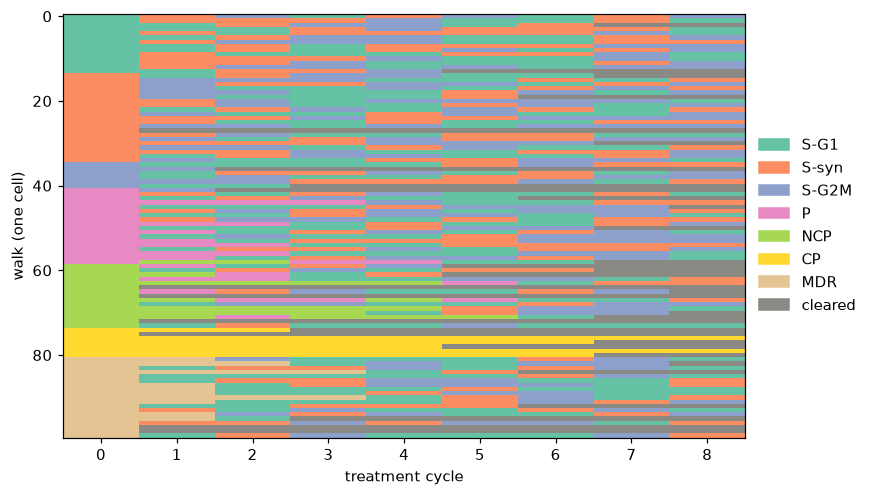

In [33]:
N_WALKS = 100
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [34]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

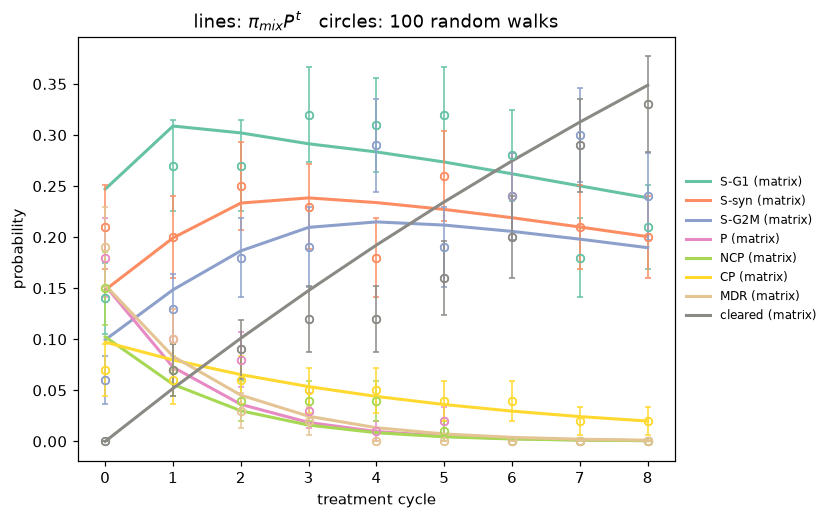

In [35]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

With 100 simulated cells random transitions have noticeable differences from the predicted proportions With 10000 simulated cells those random differences tend to average out.the gap between the simulated proportions (circles) and the theoretical probabilities (solid lines) becomes much smaller. The law of large numbers reduces random sampling variability the observed proportions meet the theortical(transition matrix)

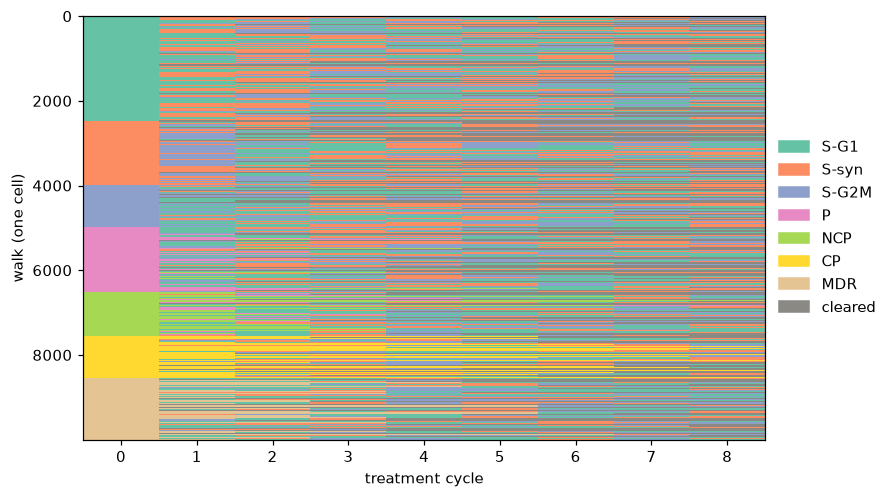

In [36]:
N_WALKS = 10_000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

In [37]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

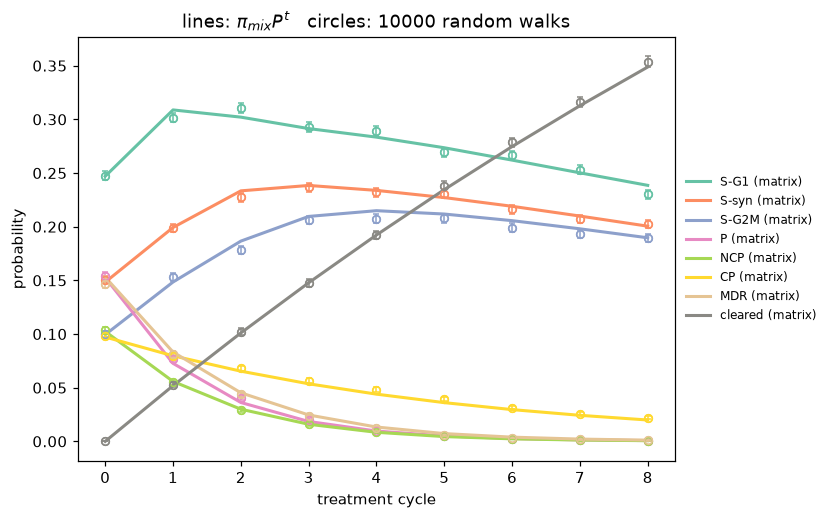

In [38]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [39]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

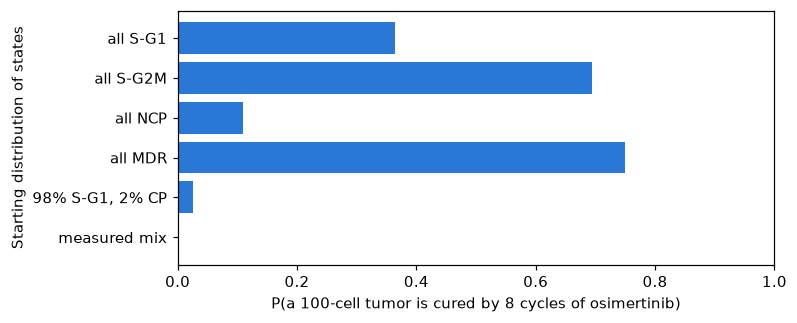

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.365,1.025,0.000
all S-G2M,0.695,0.345,0.000
all NCP,0.110,2.140,0.000
all MDR,0.750,0.275,0.000
"98% S-G1, 2% CP",0.025,3.190,0.638
measured mix,0.000,10.685,0.918


In [40]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

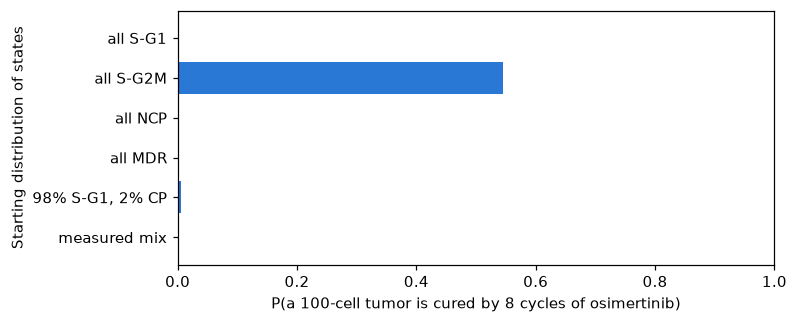

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.000,7.805,0.0
all S-G2M,0.545,0.610,0.0
all NCP,0.000,6.690,0.0
all MDR,0.000,100.000,0.0
"98% S-G1, 2% CP",0.005,6.985,0.0
measured mix,0.000,18.955,0.0


In [41]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

When the treatment is changed from osimertinib to docetaxel, the probability of completely clearing a 100-cell tumor depends strongly on its initial cell states. Tumors consisting entirely of S-G2M cells have the highest estimated cure probability, approximately 54%, while tumors consisting entirely of MDR cells have a 0% cure probability because MDR is an absorbing state under docetaxel. The other starting scenarios show very low or zero observed cure rates. This demonstrates how the initial composition of a tumor affects the effectiveness of a treatment.

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [42]:
# write a function that runs 1000 random walks and saves them
# you will use this function 100 times to generate a simulated set of tumors

# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells

# repeat for all tumors

# report mean +/- SEM for osimertinib

# compare to 10% threshold using 95% CI or a hypothesis test



In [43]:
def simulate_tumor_walks(pi0, P, n_cells, n_cycles, rng):
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)

    walks = [
        random_walk(int(s0), P, n_cycles, rng)
        for s0 in starts
    ]

    return np.array(walks)

In [44]:
def became_resistant(walk):
    persister_states = {
        OUTCOMES.index("P"),
        OUTCOMES.index("NCP")
    }

    consecutive = 0

    for state in walk:
        if state in persister_states:
            consecutive += 1
            if consecutive >= 3:
                return True
        else:
            consecutive = 0

    return False

In [45]:
test_walk = [
    OUTCOMES.index(s)
    for s in ["S-G1", "P", "P", "P", "cleared"]
]

print(became_resistant(test_walk))

True


In [46]:
def resistant_fraction(pi0, P, n_cells, n_cycles, rng):
    walks = simulate_tumor_walks(pi0, P, n_cells, n_cycles, rng)

    resistant = [became_resistant(walk) for walk in walks]

    return np.mean(resistant)

In [47]:
fraction = resistant_fraction(
    pi_mix,
    P_osi,
    1000,
    8,
    rng
)

print(f"Resistant cells: {fraction:.2%}")

Resistant cells: 12.50%


In [48]:
fractions = np.array([
    resistant_fraction(pi_mix, P_osi, 1000, 8, rng)
    for _ in range(100)
])

mean = np.mean(fractions)
sem = np.std(fractions, ddof=1) / np.sqrt(100)

print(f"Mean resistant fraction: {mean:.2%}")
print(f"SEM: {sem:.2%}")
print(f"Tumors above 10%: {np.mean(fractions > 0.10):.2%}")

Mean resistant fraction: 11.58%
SEM: 0.09%
Tumors above 10%: 98.00%


In [49]:
ci_lower = mean - 1.96 * sem
ci_upper = mean + 1.96 * sem

print(f"95% CI: [{ci_lower:.2%}, {ci_upper:.2%}]")

95% CI: [11.40%, 11.76%]


In [50]:
def random_walk_schedule(start, schedule, rng):
    path = [start]

    for P in schedule:
        path.append(step(path[-1], P, rng))

    return path

In [51]:
def simulate_tumor_walks_schedule(pi0, schedule, n_cells, rng):
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)

    walks = [
        random_walk_schedule(int(s0), schedule, rng)
        for s0 in starts
    ]

    return np.array(walks)


def resistant_fraction_schedule(pi0, schedule, n_cells, rng):
    walks = simulate_tumor_walks_schedule(
        pi0, schedule, n_cells, rng
    )

    resistant = [
        became_resistant(walk)
        for walk in walks
    ]

    return np.mean(resistant)

In [59]:
N_TUMORS = 100
N_CELLS = 1000
N_CYCLES = 8

schedules = {
    "Osimertinib": [P_osi] * N_CYCLES,
    "Docetaxel": [P_doc] * N_CYCLES,
    "Alternating OD": [
        P_osi if i % 2 == 0 else P_doc
        for i in range(N_CYCLES)
    ],
    # "Docetaxel + holiday": [P_holiday] + [P_doc] * (N_CYCLES - 1)
    "Docetaxel + holiday": [
    P_doc if i % 2 == 0 else P_holiday
    for i in range(N_CYCLES)
]
}

rows = []

for treatment, schedule in schedules.items():

    fractions = np.array([
        resistant_fraction_schedule(
            pi_mix, schedule, N_CELLS, rng
        )
        for _ in range(N_TUMORS)
    ])

    mean = np.mean(fractions)
    sd = np.std(fractions, ddof=1)
    sem = sd / np.sqrt(N_TUMORS)

    rows.append({
        "Treatment": treatment,
        "Mean %": mean * 100,
        "SD %": sd * 100,
        "SEM %": sem * 100,
        "95% CI lower": (mean - 1.96 * sem) * 100,
        "95% CI upper": (mean + 1.96 * sem) * 100,
        "Tumors > 10%": np.mean(fractions > 0.10) * 100
    })

results_resistance = pd.DataFrame(rows)

print(results_resistance.round(2).to_string(index=False))

          Treatment  Mean %  SD %  SEM %  95% CI lower  95% CI upper  Tumors > 10%
        Osimertinib   11.55  0.85   0.09         11.38         11.72          98.0
          Docetaxel    9.03  0.97   0.10          8.84          9.22          17.0
     Alternating OD   10.57  0.92   0.09         10.39         10.75          71.0
Docetaxel + holiday   10.00  1.01   0.10          9.81         10.20          48.0


In [53]:
cycle_results = []

for n_cycles in [4, 8, 12, 16]:

    schedules = {
        "Osimertinib": [P_osi] * n_cycles,
        "Docetaxel": [P_doc] * n_cycles,
        "Alternating OD": [
            P_osi if i % 2 == 0 else P_doc
            for i in range(n_cycles)
        ],
        "Docetaxel + holiday":
            [P_holiday] + [P_doc] * (n_cycles - 1)
    }

    for treatment, schedule in schedules.items():

        fractions = np.array([
            resistant_fraction_schedule(
                pi_mix, schedule, 1000, rng
            )
            for _ in range(100)
        ])

        cycle_results.append({
            "Cycles": n_cycles,
            "Treatment": treatment,
            "Mean resistant %": fractions.mean() * 100,
            "Tumors > 10%": np.mean(fractions > 0.10) * 100
        })

cycle_df = pd.DataFrame(cycle_results)

print("Percentage of tumors with more than 10% resistant cells:")

print(
    cycle_df.pivot(
        index="Cycles",
        columns="Treatment",
        values="Tumors > 10%"
    ).round(2)
)

Percentage of tumors with more than 10% resistant cells:
Treatment  Alternating OD  Docetaxel  Docetaxel + holiday  Osimertinib
Cycles                                                                
4                    47.0        7.0                  4.0         91.0
8                    79.0       14.0                 31.0         90.0
12                   74.0       17.0                 35.0         92.0
16                   74.0       13.0                 33.0         95.0


In [54]:
cycle_results = []

for treatment in [
    "Osimertinib",
    "Docetaxel",
    "Alternating OD",
    "Docetaxel + holiday"
]:
    if treatment == "Osimertinib":
        schedule = [P_osi] * 16
    elif treatment == "Docetaxel":
        schedule = [P_doc] * 16
    elif treatment == "Alternating OD":
        schedule = [P_osi if i % 2 == 0 else P_doc for i in range(16)]
    else:
        schedule = [P_holiday] + [P_doc] * 15

    tumor_walks = [
        simulate_tumor_walks_schedule(pi_mix, schedule, 1000, rng)
        for _ in range(100)
    ]

    for n_cycles in [4, 8, 12, 16]:
        fractions = np.array([
            np.mean([
                became_resistant(walk[:n_cycles + 1])
                for walk in tumor
            ])
            for tumor in tumor_walks
        ])

        cycle_results.append({
            "Treatment": treatment,
            "Cycles": n_cycles,
            "Mean resistant %": fractions.mean() * 100,
            "Tumors > 10%": np.mean(fractions > 0.10) * 100
        })

cycle_df = pd.DataFrame(cycle_results)

print(cycle_df.pivot(
    index="Cycles",
    columns="Treatment",
    values="Tumors > 10%"
).round(1))

Treatment  Alternating OD  Docetaxel  Docetaxel + holiday  Osimertinib
Cycles                                                                
4                    50.0        4.0                  3.0         87.0
8                    73.0       17.0                 38.0         97.0
12                   73.0       18.0                 40.0         97.0
16                   73.0       18.0                 40.0         97.0


<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

After 8 cycles, osimertinib alone had the highest percentage of tumors with more than 10% resistant cells (98%), followed by alternating osimertinib and docetaxel (71%), alternating docetaxel with drug holidays (48%), and docetaxel alone (17%).

Docetaxel alone had the lowest average percentage of resistant cells (9.03%), while osimertinib alone had the highest (11.55%). Alternating docetaxel with drug holidays resulted in an average of 10.00% resistant cells.

Overall, docetaxel alone performed best at limiting permanent resistance in this simulation. Alternating docetaxel with drug holidays produced more resistance than continuous docetaxel, showing that introducing drug holidays does not necessarily reduce the risk of permanent resistance.